In [1]:
# گام ۱: تولید داده‌های مصنوعی
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline

# تنظیم بذر تصادفی برای بازتولیدپذیری (Reproducibility)
np.random.seed(42)

# تولید ۱۰۰ نمونه در بازه ۰ تا ۵۰ (زمان)
x_nonlinear = np.linspace(0, 50, 100)

# تولید جمعیت باکتری با رابطه سینوسی + نویز نرمال (میانگین ۰، انحراف معیار ۵۰)
y_nonlinear = 1000 * np.sin(0.1 * x_nonlinear) + np.random.normal(0, 50, 100)

# تبدیل x به آرایه ستونی
X = x_nonlinear.reshape(-1, 1)

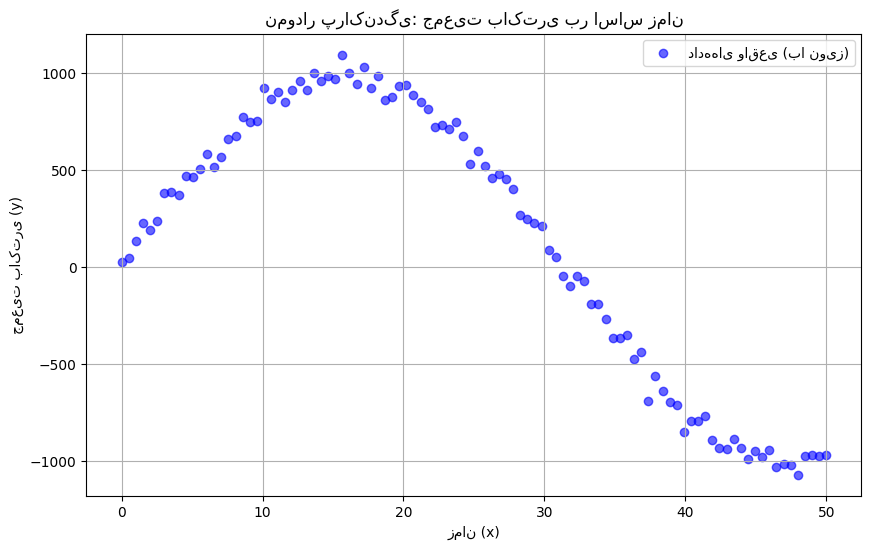

In [2]:
# گام ۲: رسم نمودار پراکندگی داده‌های خام
plt.figure(figsize=(10, 6))
plt.scatter(x_nonlinear, y_nonlinear, color='blue', alpha=0.6, label='داده‌های واقعی (با نویز)')
plt.title('نمودار پراکندگی: جمعیت باکتری بر اساس زمان')
plt.xlabel('زمان (x)')
plt.ylabel('جمعیت باکتری (y)')
plt.legend()
plt.grid(True)
plt.show()

In [3]:
# گام ۳: ساخت مدل با Pipeline (ترکیب PolynomialFeatures و LinearRegression)
degree = 3
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())

# آموزش مدل روی داده‌ها
model.fit(X, y_nonlinear)

print(f"مدل درجه {degree} با موفقیت آموزش دید.")

مدل درجه 3 با موفقیت آموزش دید.


In [4]:
# گام ۴: پیش‌بینی و محاسبه معیارهای خطا
y_pred = model.predict(X)

mse = mean_squared_error(y_nonlinear, y_pred)
r2 = r2_score(y_nonlinear, y_pred)

print(f"MSE (میانگین مربعات خطا): {mse:.2f}")
print(f"R2 Score (ضریب تعیین): {r2:.4f}")
print("-" * 30)
print("Coefficients (ضرایب):", model.named_steps['linearregression'].coef_)
print("Intercept (عرض از مبدأ):", model.named_steps['linearregression'].intercept_)

MSE (میانگین مربعات خطا): 6221.13
R2 Score (ضریب تعیین): 0.9876
------------------------------
Coefficients (ضرایب): [ 0.00000000e+00  1.84541292e+02 -8.47103485e+00  8.84862381e-02]
Intercept (عرض از مبدأ): -179.99250862535482


In [5]:
# گام ۵: بررسی تأثیر درجه چندجمله‌ای بر خطا (Overfitting)
print("بررسی تأثیر درجه چندجمله‌ای بر خطا (MSE):")
for d in [1, 2, 3, 5, 10]:
    poly_temp = PolynomialFeatures(degree=d)
    X_poly_temp = poly_temp.fit_transform(X)
    model_temp = LinearRegression()
    model_temp.fit(X_poly_temp, y_nonlinear)
    y_pred_temp = model_temp.predict(X_poly_temp)
    mse_temp = mean_squared_error(y_nonlinear, y_pred_temp)
    print(f"  درجه {d}: MSE = {mse_temp:.2f}")

بررسی تأثیر درجه چندجمله‌ای بر خطا (MSE):
  درجه 1: MSE = 174160.46
  درجه 2: MSE = 52565.18
  درجه 3: MSE = 6221.13
  درجه 5: MSE = 1912.37
  درجه 10: MSE = 15191.34


In [7]:
from sklearn.model_selection import train_test_split

# ۱. جداسازی داده‌ها به نسبت ۸۰ به ۲۰
X_train, X_test, y_train, y_test = train_test_split(X, y_nonlinear, test_size=0.2, random_state=42)

print(f"تعداد داده‌های آموزش: {X_train.shape[0]}")
print(f"تعداد داده‌های تست: {X_test.shape[0]}")

# ۲. آموزش مجدد مدل درجه ۳ روی داده‌های آموزش
model_final = make_pipeline(PolynomialFeatures(degree=3), LinearRegression())
model_final.fit(X_train, y_train)

# ۳. ارزیابی روی داده‌های تست (داده‌هایی که مدل ندیده)
y_pred_test = model_final.predict(X_test)
mse_test = mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

print(f"MSE (روی داده تست): {mse_test:.2f}")
print(f"R2 Score (روی داده تست): {r2_test:.4f}")

تعداد داده‌های آموزش: 80
تعداد داده‌های تست: 20
MSE (روی داده تست): 6820.71
R2 Score (روی داده تست): 0.9863


In [8]:
from sklearn.model_selection import cross_val_score

# انجام ۵-فولد کراس ولیدیشن روی کل داده‌ها
cv_scores = cross_val_score(model_final, X, y_nonlinear, cv=5, scoring='neg_mean_squared_error')
mse_cv = -cv_scores # تبدیل به مقدار مثبت

print(f"MSE در هر فولد: {mse_cv}")
print(f"میانگین MSE: {mse_cv.mean():.2f}")
print(f"انحراف معیار MSE: {mse_cv.std():.2f}")

MSE در هر فولد: [227337.77777272   3506.18077614  14900.33080965  13206.44032255
 385079.59627329]
میانگین MSE: 128806.07
انحراف معیار MSE: 153246.51


In [9]:
print("درجه | MSE آموزش | MSE تست")
print("-" * 35)

for d in [1, 2, 3, 5, 10, 15]:
    temp_model = make_pipeline(PolynomialFeatures(d), LinearRegression())
    temp_model.fit(X_train, y_train)

    # خطا روی آموزش
    y_train_pred = temp_model.predict(X_train)
    mse_train = mean_squared_error(y_train, y_train_pred)

    # خطا روی تست
    y_test_pred = temp_model.predict(X_test)
    mse_test = mean_squared_error(y_test, y_test_pred)

    print(f"  {d:2}  |  {mse_train:10.2f}  |  {mse_test:10.2f}")

درجه | MSE آموزش | MSE تست
-----------------------------------
   1  |   160908.16  |   228184.91
   2  |    51992.23  |    58928.99
   3  |     6117.17  |     6820.71
   5  |     2008.95  |     1609.56
  10  |    13551.34  |    22271.96
  15  |    35040.17  |    59857.66


In [10]:
from sklearn.model_selection import GridSearchCV

# تعریف مدل پایه
base_model = make_pipeline(PolynomialFeatures(), LinearRegression())

# پارامترهای جستجو (درجه‌های ۱ تا ۷)
param_grid = {'polynomialfeatures__degree': [1, 2, 3, 4, 5, 6, 7]}

# جستجوی شبکه‌ای با کراس ولیدیشن ۵ تایی
grid_search = GridSearchCV(base_model, param_grid, cv=5, scoring='neg_mean_squared_error')
grid_search.fit(X_train, y_train)

print(f"بهترین درجه پیدا شده: {grid_search.best_params_['polynomialfeatures__degree']}")
print(f"بهترین MSE (روی اعتبارسنجی): {-grid_search.best_score_:.2f}")

بهترین درجه پیدا شده: 5
بهترین MSE (روی اعتبارسنجی): 2447.74


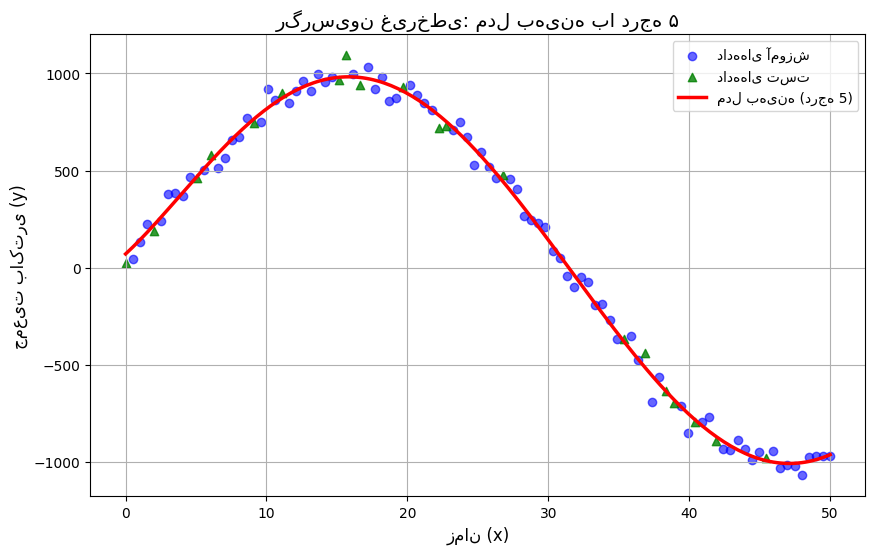

In [12]:
# گام ۶: استفاده از بهترین مدل (درجه ۵) برای رسم نمودار نهایی
best_degree = 5
model_best = make_pipeline(PolynomialFeatures(best_degree), LinearRegression())
model_best.fit(X_train, y_train) # آموزش روی داده‌های Train

# ساخت بازه پیوسته برای رسم خط
x_plot = np.linspace(0, 50, 200).reshape(-1, 1)
y_plot = model_best.predict(x_plot)

plt.figure(figsize=(10, 6))
# رسم داده‌های آموزش و تست با رنگ‌های متفاوت
plt.scatter(X_train, y_train, color='blue', alpha=0.6, label='داده‌های آموزش')
plt.scatter(X_test, y_test, color='green', alpha=0.8, marker='^', label='داده‌های تست')
# رسم خط مدل بهینه
plt.plot(x_plot, y_plot, color='red', linewidth=2.5, label=f'مدل بهینه (درجه {best_degree})')

plt.title('رگرسیون غیرخطی: مدل بهینه با درجه ۵', fontsize=14)
plt.xlabel('زمان (x)', fontsize=12)
plt.ylabel('جمعیت باکتری (y)', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

In [13]:
!pip install gradio

In [15]:
import gradio as gr

# تابع پیش‌بینی برای Gradio
def predict_population(time):
    # تبدیل ورودی به آرایه دو بعدی (چون مدل این شکل را می‌خواهد)
    input_array = np.array([[time]])
    prediction = model_best.predict(input_array)[0]
    return f"جمعیت پیش‌بینی شده: {prediction:.2f}"

# ساخت رابط کاربری
interface = gr.Interface(
    fn=predict_population,
    inputs=gr.Slider(minimum=0, maximum=50, step=0.1, label="زمان (x) را انتخاب کنید"),
    outputs=gr.Textbox(label="نتیجه پیش‌بینی"),
    title="پیش‌بینی جمعیت باکتری (رگرسیون غیرخطی)",
    description="مدل چندجمله‌ای درجه ۵ آموزش‌دیده روی داده‌های سینوسی. اسلایدر را حرکت دهید تا جمعیت پیش‌بینی شود."
)

# اجرای رابط کاربری در کولب
interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fa1c09b52758f176ac.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
